Dataset loaded successfully!
   Temperature  Humidity  Wind Speed  Precipitation (%)    Cloud Cover  \
0         14.0        73         9.5               82.0  partly cloudy   
1         39.0        96         8.5               71.0  partly cloudy   
2         30.0        64         7.0               16.0          clear   
3         38.0        83         1.5               82.0          clear   
4         27.0        74        17.0               66.0       overcast   

   Atmospheric Pressure  UV Index  Season  Visibility (km)  Location  \
0               1010.82         2  Winter              3.5    inland   
1               1011.43         7  Spring             10.0    inland   
2               1018.72         5  Spring              5.5  mountain   
3               1026.25         7  Spring              1.0   coastal   
4                990.67         1  Winter              2.5  mountain   

  Weather Type  
0        Rainy  
1       Cloudy  
2        Sunny  
3        Sunny  
4       

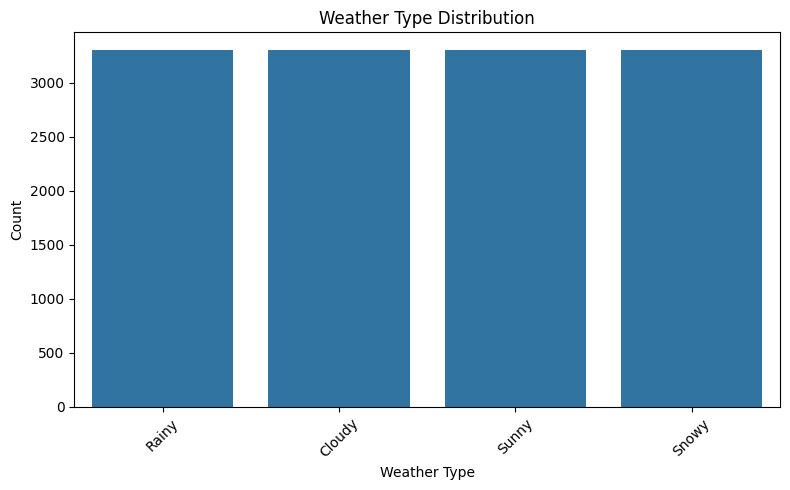


Input Features:
   Temperature  Humidity  Wind Speed  Precipitation (%)    Cloud Cover  \
0         14.0        73         9.5               82.0  partly cloudy   
1         39.0        96         8.5               71.0  partly cloudy   
2         30.0        64         7.0               16.0          clear   
3         38.0        83         1.5               82.0          clear   
4         27.0        74        17.0               66.0       overcast   

   Atmospheric Pressure  UV Index  Season  Visibility (km)  Location  
0               1010.82         2  Winter              3.5    inland  
1               1011.43         7  Spring             10.0    inland  
2               1018.72         5  Spring              5.5  mountain  
3               1026.25         7  Spring              1.0   coastal  
4                990.67         1  Winter              2.5  mountain  

Target Values:
0     Rainy
1    Cloudy
2     Sunny
3     Sunny
4     Rainy
Name: Weather Type, dtype: object

C

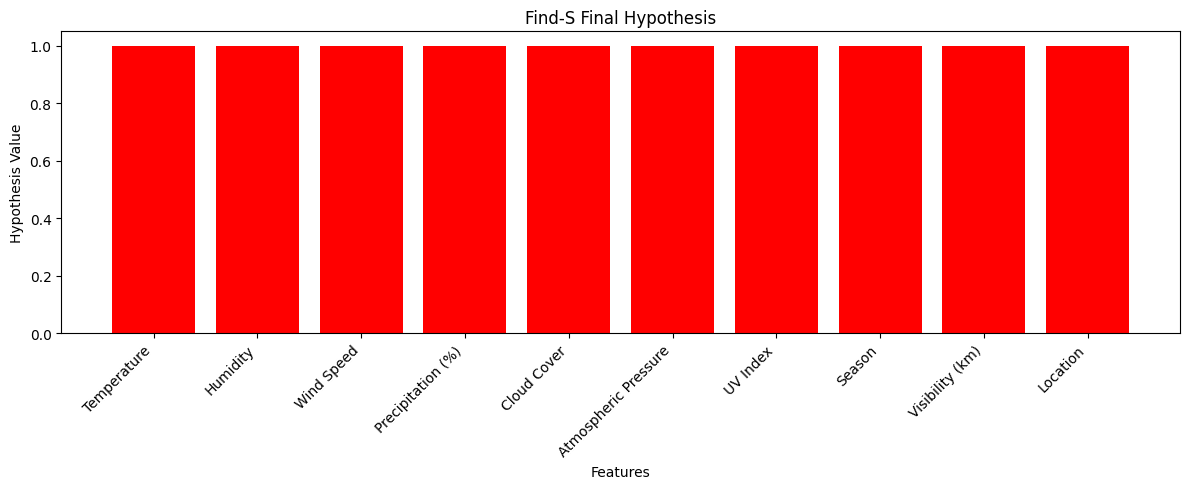


Sample Input:
Temperature                    Medium
Humidity                       Medium
Wind Speed                     Medium
Precipitation (%)                High
Cloud Cover             partly cloudy
Atmospheric Pressure           Medium
UV Index                       Medium
Season                         Winter
Visibility (km)                   Low
Location                       inland
Name: 0, dtype: object


Actual Weather Type: Rainy

Find-S Algorithm Completed Successfully!
Positive Class: Sunny
Number of Training Examples: 13200
Number of Features: 10
Learned Hypothesis: ['?', '?', '?', '?', '?', '?', '?', '?', '?', '?']


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML

# 2. Load Dataset
data = pd.read_csv('/content/weather_classification_data.csv')
data.columns = data.columns.str.strip()

print("Dataset loaded successfully!")
print(data.head())
print("Dataset shape:", data.shape)

# 3. Data Preprocessing
data = data.dropna()
data = data.drop_duplicates().copy()

print("\nData cleaned successfully!")
print("Dataset shape after cleaning:", data.shape)

# 4. Display Dataset Information
print("\nDataset Information:")
data.info()

print("\nColumn Names:")
print(data.columns.tolist())

print("\nWeather Type Distribution:")
print(data["Weather Type"].value_counts())

# 5. Visualize Weather Type Distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=data, x="Weather Type")
plt.title("Weather Type Distribution")
plt.xlabel("Weather Type")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 6. Select Input Features and Target
target_column = "Weather Type"

X = data.drop(columns=[target_column]).copy()
y = data[target_column].copy()

print("\nInput Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

# 7. Convert Numerical Features into Categories
for column in X.columns:
    if pd.api.types.is_numeric_dtype(X[column]):
        X[column] = pd.qcut(
            X[column].rank(method="first"),
            q=3,
            labels=["Low", "Medium", "High"]
        ).astype(str)
    else:
        X[column] = X[column].astype(str)

print("\nCategorical Features:")
print(X.head())

# 8. Convert Target into Positive and Negative Examples
positive_class = "Sunny"

y_binary = y.apply(
    lambda value: "Yes"
    if str(value).strip().casefold() == positive_class.casefold()
    else "No"
)

print("\nTarget after conversion:")
print(y_binary.value_counts())

# 9. Initialize Find-S Hypothesis
hypothesis = ["Ø"] * len(X.columns)

print("\nInitial Hypothesis:")
print(hypothesis)

# 10. Apply Find-S Algorithm
for index, row in X.iterrows():
    if y_binary.loc[index] == "Yes":
        for i in range(len(hypothesis)):
            if hypothesis[i] == "Ø":
                hypothesis[i] = row.iloc[i]
            elif hypothesis[i] != row.iloc[i]:
                hypothesis[i] = "?"

print("\nFinal Hypothesis:")
print(hypothesis)

# 11. Display Hypothesis with Feature Names
print("\nFinal Hypothesis of Find-S Algorithm:")
for feature, value in zip(X.columns, hypothesis):
    print(feature, ":", value)

# 12. Visualize Final Hypothesis (Red Bars)
hypothesis_values = [
    0 if value == "Ø" else 1 if value == "?" else 2
    for value in hypothesis
]

plt.figure(figsize=(12, 5))
plt.bar(X.columns, hypothesis_values, color="red")
plt.title("Find-S Final Hypothesis")
plt.xlabel("Features")
plt.ylabel("Hypothesis Value")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 13. Test Hypothesis on a Sample
sample = X.iloc[0]

result = all(
    hypothesis[i] == "?" or hypothesis[i] == sample.iloc[i]
    for i in range(len(hypothesis))
)

print("\nSample Input:")
print(sample)

prediction = "Sunny" if result else "Not Sunny"

display(
    HTML(
        f"<h3 style='color:red;'>Predicted Concept: {prediction}</h3>"
    )
)

print("Actual Weather Type:", y.iloc[0])

# 14. Final Result
print("\nFind-S Algorithm Completed Successfully!")
print("Positive Class:", positive_class)
print("Number of Training Examples:", len(X))
print("Number of Features:", len(X.columns))
print("Learned Hypothesis:", hypothesis)
